# Grouped Monthly CPR Forecasting with LightGBM

One observation is **one loan group in one month**. Loans are grouped by agency and original coupon. Two shared LightGBM models predict next-month **turnover SMM** and **refinance SMM** changes; known balance weights combine their forecasts into portfolio CPR.

**This is a single-file notebook.** It includes the full modeling code, an optional raw Fannie/Freddie reconstruction pipeline, embedded aggregated inputs, and executed results. The default mode retrains from the embedded group-month data. No companion files or external downloads are needed.

For raw-data reconstruction, set `REBUILD_FROM_RAW = True` and update the archive paths below. The raw-preparation cell is collapsed to keep the main model readable; its source remains inside this notebook for inspection and adaptation.

In [1]:
from pathlib import Path
import ctypes, json, sys, warnings, base64, hashlib, io, zipfile, contextlib, calendar
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# On macOS, use an existing OpenMP runtime when available.
if sys.platform == "darwin":
    for library in [Path(sys.prefix) / "lib/libomp.dylib", Path("/opt/anaconda3/lib/libomp.dylib")]:
        if library.exists():
            ctypes.CDLL(str(library), mode=ctypes.RTLD_GLOBAL)
            break
import lightgbm as lgb
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .18, "legend.frameon": False})


import pyarrow as pa
import pyarrow.csv as pacsv


### Single-file inputs and optional raw reconstruction

The default mode reads the small grouped dataset embedded in this notebook's metadata and retrains the models. To rebuild from your original loan archives, set the raw paths and `REBUILD_FROM_RAW = True`.

The optional pipeline below defines all field mappings, prior-active risk-set construction, incentive aggregation and component-label estimation. Fannie uses 113 pipe-delimited fields; Freddie origination/performance use 31/35 fields. Samples retain complete loan histories within the 80 MB / 30 MB quarterly budgets.

Component labels for target month t may use payoff outcomes observed in t to estimate the split. Those are training answers; predictors use only lagged labels/reference speeds from t-1 or earlier. No payoff reason is directly observed. The raw source is the original archives, not a slim event table that may have discarded maturity and active-status fields.

In [2]:
# Default: use the aggregated panel embedded in this notebook.
REBUILD_FROM_RAW = False
NOTEBOOK_FILE = None  # Set this path only if the kernel starts in a different folder.
RAW_ROOT = Path.cwd()  # Directory containing your data/ folder; used only in raw mode.
FANNIE_ARCHIVE = RAW_ROOT / "data/fannie/Performance_All.zip"
FREDDIE_DIRECTORY = RAW_ROOT / "data/freddie/raw"
FREDDIE_FULL_ARCHIVE = FREDDIE_DIRECTORY / "full_set_standard_historical_data.zip"

setup = {'candidate': 'amine_incentives_agency_rate_components_lgbm_delta_7_s1',
 'recipe': {'grain': 'agency_rate',
            'package': 'amine_incentives',
            'scope': 'components',
            'family': 'lgbm_delta',
            'config': {'num_leaves': 7},
            'shrink': 1.0},
 'features': ['wala',
              'mean_note_rate',
              'mean_orig_rate',
              'mean_fico',
              'mean_ltv',
              'mean_cltv',
              'mean_dti',
              'mean_orig_upb',
              'mean_remaining',
              'orig_rate_std',
              'age_std',
              'young_share',
              'delinq30_share',
              'delinq90_share',
              'modified_share',
              'forbearance_share',
              'owner_share',
              'cashout_orig_share',
              'refi_orig_share',
              'fannie_share',
              'mean_incentive',
              'positive_share',
              'above05_share',
              'above10_share',
              'lockin_share',
              'market_rate_known',
              'market_change_known',
              'lag_smm',
              'lag_smm_change',
              'lag_smm_mean3',
              'lag_smm_mean12',
              'lag_turn',
              'lag_refi',
              'lag_turn_change',
              'lag_refi_change',
              'season_sin',
              'season_cos',
              'days_in_month',
              'weekdays',
              'global_lag_smm',
              'global_lag_change',
              'lag_turnover_baseline',
              'rate_ratio',
              'dollar_savings',
              'savings_per100k',
              'save100_share',
              'save250_share'],
 'parameters': {'objective': 'regression_l1',
                'n_estimators': 100,
                'learning_rate': 0.05,
                'max_depth': 3,
                'num_leaves': 7,
                'min_child_samples': 20,
                'reg_lambda': 1.0,
                'random_state': 42,
                'n_jobs': 2,
                'verbosity': -1,
                'deterministic': True,
                'force_col_wise': True},
 'training_start_t': 24012,
 'test_start_t': 24264,
 'test_end_t': 24314,
 'validation_folds': [{'train_end_year': 2009, 'first_year': 2010, 'last_year': 2012},
                      {'train_end_year': 2012, 'first_year': 2013, 'last_year': 2015},
                      {'train_end_year': 2015, 'first_year': 2016, 'last_year': 2018},
                      {'train_end_year': 2018, 'first_year': 2019, 'last_year': 2021}],
 'reference_validation': [{'fold': '2010-2012',
                           'mae': 1.8051193914056265,
                           'baseline_mae': 2.5696431631038448,
                           'relative_mae': 0.7024786232284649},
                          {'fold': '2013-2015',
                           'mae': 1.3600445656343427,
                           'baseline_mae': 1.6341184902834933,
                           'relative_mae': 0.8322802622460975},
                          {'fold': '2016-2018',
                           'mae': 1.0047317323006044,
                           'baseline_mae': 1.4363176340343022,
                           'relative_mae': 0.6995191791097994},
                          {'fold': '2019-2021',
                           'mae': 2.30355185247309,
                           'baseline_mae': 2.9414328241534298,
                           'relative_mae': 0.7831393712470971}],
 'selection_note': 'Fixed grouped candidate selected within the incentive-feature experiment using four '
                   'pre-2022 validation periods. The historical test years had already been explored.',
 'source_selection_sha256': '3d5668f9a4e0df8c85959166cd973bec1f24cf1b4db844fdd5a264ad3f399ed4',
 'data_note': 'Prepared origin-known group-month inputs and heuristic component targets. No individual loan '
              'records in this package.'}
FEATURES = setup["features"]
TARGETS = ["target_turn", "target_refi"]
LAGS = ["lag_turn", "lag_refi"]
PARAMS = setup["parameters"]


In [3]:
def read_embedded_inputs():
    if NOTEBOOK_FILE is not None:
        candidates = [Path(NOTEBOOK_FILE)]
    else:
        folders = [Path.cwd(), Path.cwd() / "experiments/cpr_amine_features_v7"]
        candidates = []
        for folder in folders:
            preferred = folder / "grouped_monthly_lightgbm.ipynb"
            candidates += [preferred] if preferred.exists() else []
            candidates += sorted(folder.glob("*.ipynb"))
    for filename in dict.fromkeys(candidates):
        metadata = json.loads(filename.read_text()).get("metadata", {})
        data = metadata.get("cpr_single_file", {})
        if data.get("id") == "grouped-monthly-lightgbm-v7-standalone":
            raw_bytes = base64.b64decode(data["panel_parquet_b64"])
            if hashlib.sha256(raw_bytes).hexdigest() != data["panel_sha256"]:
                raise ValueError("Embedded panel checksum mismatch")
            return data, pd.read_parquet(io.BytesIO(raw_bytes))
    raise FileNotFoundError("Set NOTEBOOK_FILE to the location of this .ipynb file.")

embedded, embedded_panel = read_embedded_inputs()
PMMS_RATES = pd.DataFrame(embedded["pmms_monthly"]).set_index("t").rate30


In [4]:
END = 24314
TRAIN_START = 2001 * 12
VARIANTS = {"lag1": (1,)}
FANNIE_FIELDS = {2: 'loan_id',
 3: 'period',
 8: 'orig_rate',
 9: 'cur_rate',
 10: 'orig_upb',
 12: 'cur_upb',
 13: 'orig_term',
 14: 'orig_date',
 15: 'first_pay',
 16: 'age',
 17: 'remaining',
 19: 'maturity',
 20: 'ltv',
 21: 'cltv',
 22: 'borrowers',
 23: 'dti',
 24: 'fico',
 26: 'first_buyer',
 27: 'purpose',
 28: 'property',
 29: 'units',
 30: 'occupancy',
 31: 'state',
 35: 'amort',
 40: 'dlq',
 42: 'mod',
 44: 'zero',
 45: 'zero_date',
 46: 'removal_upb',
 102: 'assist',
 111: 'new_fico'}
FREDDIE_ORIG = {1: 'fico',
 2: 'first_pay',
 4: 'maturity',
 7: 'units',
 8: 'occupancy',
 9: 'cltv',
 10: 'dti',
 11: 'orig_upb',
 12: 'ltv',
 13: 'orig_rate',
 16: 'amort',
 20: 'loan_id',
 21: 'purpose',
 22: 'orig_term',
 23: 'borrowers',
 31: 'vantage'}
FREDDIE_PERF = {1: 'loan_id',
 2: 'period',
 3: 'cur_upb',
 4: 'dlq',
 5: 'age',
 6: 'remaining',
 8: 'mod',
 9: 'zero',
 10: 'zero_date',
 11: 'cur_rate',
 27: 'removal_upb',
 30: 'assist'}
TEXT = {'amort',
 'assist',
 'channel',
 'dlq',
 'first_buyer',
 'first_pay',
 'loan_id',
 'maturity',
 'mod',
 'occupancy',
 'orig_date',
 'period',
 'property',
 'purpose',
 'state',
 'zero',
 'zero_date'}
SUM_COLS=['risk_bal','known_bal','pay_bal','maturity_bal','credit_bal','other_bal','unknown_bal','rows','known_rows','fallback_bal']
NUMERICS=['note_rate','orig_rate','age','fico','ltv','cltv','dti','orig_upb','remaining']
SHARES={'young':lambda x:x.age.lt(24),'delinq30':lambda x:x.dlq_num.ge(1),'delinq90':lambda x:x.dlq_num.ge(3),'modified':lambda x:x['mod'].isin(['Y','P']),'forbearance':lambda x:x.assist.eq('F'),'owner':lambda x:x.occupancy.eq('P'),'cashout_orig':lambda x:x.purpose.eq('C'),'refi_orig':lambda x:x.purpose.isin(['C','R'] if x.agency.iloc[0]=='fannie' else ['C','N','R'])}

COMPOSITION = ['wala', 'mean_note_rate', 'mean_orig_rate', 'mean_fico', 'mean_ltv', 'mean_cltv', 'mean_dti', 'mean_orig_upb', 'mean_remaining', 'orig_rate_std', 'age_std', 'young_share', 'delinq30_share', 'delinq90_share', 'modified_share', 'forbearance_share', 'owner_share', 'cashout_orig_share', 'refi_orig_share', 'fannie_share', 'mean_incentive', 'positive_share', 'above05_share', 'above10_share', 'lockin_share']
HISTORY = ['lag_smm', 'lag_smm_change', 'lag_smm_mean3', 'lag_smm_mean12', 'lag_turn', 'lag_refi', 'lag_turn_change', 'lag_refi_change', 'turnover_index_lag']
CALENDAR = ['season_sin', 'season_cos', 'days_in_month', 'weekdays']
MARKET = ['market_rate_known', 'market_change_known']
KEYS = ['target_t', 'groupid', 'agency', 'vintage_band', 'rate_bin']
INC_FEATURES = ['rate_ratio', 'dollar_savings', 'savings_per100k', 'save100_share', 'save250_share']

def month_index(series,agency):
    s=series.fillna('').astype(str)
    if agency=='fannie':y=pd.to_numeric(s.str[2:6],errors='coerce');m=pd.to_numeric(s.str[:2],errors='coerce')
    else:y=pd.to_numeric(s.str[:4],errors='coerce');m=pd.to_numeric(s.str[4:6],errors='coerce')
    return (y*12+m-1).where(y.between(1900,2100)&m.between(1,12))


def read_fields(archive,member,mapping,width,budget=None,drop_last=False):
    with archive.open(member) as f:raw=f.read() if budget is None else f.read(budget)
    complete=budget is None or len(raw)<budget
    if not complete:raw=raw[:raw.rfind(b'\n')+1]
    assert len(raw.split(b'\n',1)[0].rstrip(b'\r').split(b'|'))==width,(member,'layout')
    names=[f'c{i}' for i in range(1,width+1)]
    columns=[f'c{i}' for i in mapping]
    table=pacsv.read_csv(pa.BufferReader(raw),read_options=pacsv.ReadOptions(column_names=names,block_size=2**20),parse_options=pacsv.ParseOptions(delimiter='|',quote_char=False),convert_options=pacsv.ConvertOptions(include_columns=columns,column_types={n:pa.string() for n in columns},strings_can_be_null=False))
    df=table.to_pandas().rename(columns={f'c{i}':name for i,name in mapping.items()})
    if drop_last and not complete:df=df[df.loan_id.ne(df.loan_id.iloc[-1])].copy()
    for col in df.columns:
        if col not in TEXT:df[col]=pd.to_numeric(df[col].replace('',np.nan),errors='coerce')
    return df


def risk_rows(df,agency,quarter):
    assert not df.duplicated(['loan_id','period']).any(),(agency,quarter,'duplicates')
    df=df.copy()
    df['t']=month_index(df.period,agency)
    assert df.t.notna().all()
    df['t']=df.t.astype(int)
    df=df.sort_values(['loan_id','t'],kind='stable').reset_index(drop=True)
    anchor=df.groupby('loan_id',sort=False).first()
    term=anchor.orig_term
    amort=anchor.amort
    if agency=='fannie':vintage=month_index(anchor.orig_date,'fannie')//12
    else:vintage=pd.Series(int(quarter[:4]),index=anchor.index,dtype=float)
    good=term.eq(360)&amort.eq('FRM')&vintage.between(2000,2025)
    df=df[df.loan_id.map(good).fillna(False)].reset_index(drop=True)
    if df.empty:return df,{'sample_rows':0}
    group=df.groupby('loan_id',sort=False)
    first_rate=anchor.orig_rate.clip(lower=0,upper=20)
    rate_bin=np.floor(first_rate).clip(0,10).fillna(-1).astype(int)
    df['rate_bin']=df.loan_id.map(rate_bin).astype(int)
    df['vintage_band']=(df.loan_id.map(vintage)//5*5).astype(int)
    df['agency']=agency
    df['groupid']=agency+'_'+df.vintage_band.astype(str)+'_'+df.rate_bin.astype(str)
    next_id=df.loan_id.shift(-1)
    next_t=df.t.shift(-1)
    known=next_id.eq(df.loan_id)&next_t.eq(df.t+1)
    next_zero=df.zero.shift(-1).fillna('')
    next_date=month_index(df.zero_date.shift(-1),agency)
    maturity=month_index(df.maturity,agency)
    event_month=next_date.where(next_date.notna(),df.t+1)
    mature_next=event_month.ge(maturity)
    mat_known=maturity.notna()
    terminal=df.zero.fillna('').ne('')
    prior_terminal=terminal.groupby(df.loan_id,sort=False).cumsum()
    eligible=prior_terminal.eq(0)&~terminal
    balance=df.cur_upb.copy()
    fallback=(~(balance>0))&df.age.between(0,6)&(df.orig_upb>0)
    balance=balance.mask(fallback,df.orig_upb)
    eligible &= (balance>0)&balance.notna()&df.t.add(1).between(2000*12,END)
    df['target_t']=df.t+1
    df['risk_bal']=balance
    df['known']=known
    # A code-01 event with unknown legal maturity is an unknown label, not an assumed early payoff.
    label_known=known&(~next_zero.eq('01')|mat_known)
    df['known_bal']=balance*label_known
    df['pay_bal']=balance*(label_known&next_zero.eq('01')&~mature_next)
    df['maturity_bal']=balance*(known&next_zero.eq('01')&mature_next)
    df['credit_bal']=balance*(known&next_zero.isin(['02','03','09','15']))
    df['other_bal']=balance*(known&~next_zero.isin(['','01','02','03','09','15']))
    df['unknown_bal']=balance*(~label_known)
    df['rows']=1
    df['known_rows']=label_known.astype(int)
    df['fallback_bal']=balance*fallback
    df['note_rate']=df.cur_rate.where(df.cur_rate.notna(),df.orig_rate)
    df['fico']=df.fico.mask(df.fico.eq(9999))
    if 'new_fico' in df:df['fico']=df.fico.fillna(df.new_fico)
    for col in ['ltv','cltv','dti']:
        df[col]=df[col].mask(df[col].eq(999))
    df['age_bucket']=np.searchsorted([12,36,60],df.age.fillna(0).to_numpy()+1,side='left')
    df['dlq_num']=pd.to_numeric(df.dlq,errors='coerce')
    audit={'sample_rows':len(df),'loans':df.loan_id.nunique(),'risk_rows':int(eligible.sum()),'masked_balance_rows':int((fallback&eligible).sum()),'unknown_label_rows':int((~label_known&eligible).sum()),'unknown_maturity_code01':int((known&next_zero.eq('01')&~mat_known&eligible).sum()),'maturity_rows':int((known&next_zero.eq('01')&mature_next&eligible).sum()),'first_target':int(df.target_t[eligible].min()) if eligible.any() else None,'last_target':int(df.target_t[eligible].max()) if eligible.any() else None}
    return df.loc[eligible].copy(),audit


def aggregate(df,rates):
    keys=['target_t','groupid','agency','vintage_band','rate_bin']
    for col in NUMERICS:
        valid=df[col].notna()&np.isfinite(df[col])
        df['sum_'+col]=df[col].fillna(0)*df.risk_bal*valid
        df['den_'+col]=df.risk_bal*valid
    for name,fn in SHARES.items():df['sum_'+name]=df.risk_bal*fn(df).fillna(False)
    for col in ['orig_rate','age']:
        df['sum2_'+col]=df[col].fillna(0)**2*df.risk_bal*df[col].notna()
    extras=[c for c in df if c.startswith(('sum_','den_','sum2_'))]
    panel=df.groupby(keys,observed=True,sort=False)[SUM_COLS+extras].sum().reset_index()
    cells=[]
    for variant,lags in VARIANTS.items():
        market=np.mean([rates.reindex(df.target_t.to_numpy()-lag).to_numpy() for lag in lags],axis=0)
        assert np.isfinite(market).all()
        inc=df.note_rate.to_numpy()-market
        df['inc_class']=np.select([inc<-.75,inc<0],[0,1],default=2)
        for name,arr in [('incentive',inc),('positive',inc>0),('above05',inc>.5),('above10',inc>1),('lockin',inc<-2)]:
            df['sum_'+name]=arr*df.risk_bal
        inc_features=df.groupby(keys,observed=True,sort=False)[['sum_incentive','sum_positive','sum_above05','sum_above10','sum_lockin']].sum().reset_index()
        inc_features['variant']=variant
        c=df.groupby(keys+['age_bucket','inc_class'],observed=True,sort=False)[['known_bal','pay_bal','known_rows']].sum().reset_index()
        c['variant']=variant
        cells.append(c)
        if variant=='lag1':inc_panels=[]
        inc_panels.append(inc_features)
    return panel,pd.concat(cells,ignore_index=True),pd.concat(inc_panels,ignore_index=True)


def turnover_baseline(cells,all_otm=False):
    eligible=cells.inc_class.lt(2) if all_otm else cells.inc_class.eq(1)
    near=cells[eligible].groupby(['agency','target_t','age_bucket'])[['known_rows','known_bal','pay_bal']].sum()
    fullmonths=range(2000*12,2026*12+3)
    records=[]
    for agency in ['fannie','freddie']:
        values={}
        for age in range(4):
            ix=pd.MultiIndex.from_product([[agency],fullmonths,[age]],names=near.index.names)
            age_values=near.reindex(ix,fill_value=0).droplevel(['agency','age_bucket'])
            values[age]=age_values
        all_values=sum(values.values())
        for age in range(4):
            options=[(f'age_{n}m',values[age].rolling(n,min_periods=1).sum()) for n in [1,6,12,24,60]]
            options += [(f'allages_{n}m',all_values.rolling(n,min_periods=1).sum()) for n in [1,6,12,60]]
            result=pd.DataFrame(index=pd.Index(fullmonths,name='target_t'),columns=['baseline','source'])
            for label,data in options:
                use=result.baseline.isna()&data.known_rows.ge(2000)&data.known_bal.gt(0)
                result.loc[use,'baseline']=data.loc[use,'pay_bal']/data.loc[use,'known_bal']
                result.loc[use,'source']=label
            # Explicit sparse fallback, never invent zero for no reference exposure.
            data=all_values.rolling(60,min_periods=1).sum()
            use=result.baseline.isna()&data.known_bal.gt(0)
            result.loc[use,'baseline']=data.loc[use,'pay_bal']/data.loc[use,'known_bal']
            result.loc[use,'source']='sparse_allages_60m'
            result['agency']=agency;result['age_bucket']=age
            records.append(result.reset_index())
    out=pd.concat(records,ignore_index=True)
    out['baseline']=pd.to_numeric(out.baseline,errors='coerce')
    return out


def decompose(cells,baseline_type):
    base=turnover_baseline(cells,all_otm=baseline_type=='all_otm')
    c=cells.merge(base,on=['agency','target_t','age_bucket'],how='left',validate='many_to_one')
    negative=c.inc_class.lt(2)
    c['turn_amount']=np.where(negative,c.pay_bal,np.minimum(c.known_bal*c.baseline,c.pay_bal))
    c.loc[c.pay_bal.eq(0),'turn_amount']=0.
    c['refi_amount']=c.pay_bal-c.turn_amount
    valid=c.turn_amount.notna()&c.refi_amount.notna()
    c['component_exposure']=c.known_bal*valid
    c['base_num']=c.baseline.fillna(0)*c.known_bal
    c['base_den']=c.known_bal*c.baseline.notna()
    group=c.groupby(KEYS)[['turn_amount','refi_amount','component_exposure','base_num','base_den']].sum().reset_index()
    group['baseline_type']=baseline_type
    base['baseline_type']=baseline_type
    base['variant']=cells.variant.iloc[0]
    return group,base


def grain_panel(base,inc,components,grain):
    if grain=='pooled':
        for frame in [base,inc,components]:frame['gid']='all'
    elif grain=='agency_rate':
        for frame in [base,inc,components]:frame['gid']=frame.agency+'_'+frame.rate_bin.astype(str)
    else:
        for frame in [base,inc,components]:frame['gid']=frame.groupid
    keys=['target_t','gid']
    bcols=[c for c in base if c not in KEYS+['gid']]
    b=base.groupby(keys)[bcols].sum()
    b['fannie_bal']=base.assign(fannie_bal=np.where(base.agency.eq('fannie'),base.risk_bal,0)).groupby(keys).fannie_bal.sum()
    i=inc.groupby(keys)[[c for c in inc if c.startswith('sum_')]].sum()
    z=components.groupby(keys)[['turn_amount','refi_amount','component_exposure','base_num','base_den']].sum()
    p=b.join(i).join(z).reset_index().rename(columns={'target_t':'t','gid':'groupid'})
    p['actual_smm']=p.pay_bal/p.known_bal
    p['actual_cpr']=100*(1-(1-p.actual_smm)**12)
    p['turn_smm']=p.turn_amount/p.known_bal
    p['refi_smm']=p.refi_amount/p.known_bal
    valid=p.component_exposure.ge(p.known_bal*(1-1e-10))
    p.loc[~valid,['turn_smm','refi_smm']]=np.nan
    assert np.allclose((p.turn_smm+p.refi_smm)[valid],p.actual_smm[valid],atol=1e-12)
    for col in NUMERICS:p['mean_'+col]=p['sum_'+col]/p['den_'+col].replace(0,np.nan)
    p['wala']=p.mean_age
    for col in ['orig_rate','age']:
        p[col+'_std']=np.sqrt(np.maximum(0,p['sum2_'+col]/p['den_'+col].replace(0,np.nan)-p['mean_'+col]**2))
    for name in SHARES:p[name+'_share']=p['sum_'+name]/p.risk_bal
    for name in ['incentive','positive','above05','above10','lockin']:
        p['mean_incentive' if name=='incentive' else name+'_share']=p['sum_'+name]/p.risk_bal
    p['fannie_share']=p.fannie_bal/p.risk_bal
    p['turnover_index_raw']=p.base_num/p.base_den.replace(0,np.nan)
    p['coverage']=p.known_bal/p.risk_bal
    return p.sort_values(['t','groupid']).reset_index(drop=True)


def payment(balance,rate,months):
    r=np.asarray(rate,dtype=float)/1200;n=np.maximum(1,np.asarray(months,dtype=float))
    with np.errstate(divide='ignore',invalid='ignore'):
        factor=r/(-np.expm1(-n*np.log1p(r)))
    factor=np.where(r==0,1/n,factor)
    return np.asarray(balance)*factor

def construct_model_rows(panel,pooled,report_lag=1,variant='lag1'):
    months=pd.Index(range(int(pooled.t.min()),int(pooled.t.max())+1),name='t')
    global_=pooled.set_index('t').reindex(months)
    total=global_.actual_smm
    turn=global_.turn_smm
    refi=global_.refi_smm
    rates=PMMS_RATES
    offsets={'lag1':[1],'lag2':[2],'lag3':[3],'mean3':[1,2,3]}[variant]
    market=np.mean([rates.reindex(months-k).to_numpy() for k in offsets],axis=0)
    previous_market=np.mean([rates.reindex(months-k-1).to_numpy() for k in offsets],axis=0)
    pieces=[]
    for gid,group in panel.groupby('groupid',observed=True,sort=True):
        z=group.set_index('t').reindex(months)
        f=pd.DataFrame(index=months)
        f['t']=months
        f['groupid']=str(gid)
        f['origin_report_t']=months-report_lag
        known=z.shift(report_lag-1)
        for name in COMPOSITION:f[name]=known[name]
        f['market_rate_known']=market
        f['market_change_known']=market-previous_market
        f['mean_incentive']=f.mean_note_rate-f.market_rate_known
        f['wala']=f.wala+report_lag
        f['mean_remaining']=(f.mean_remaining-report_lag).clip(lower=0)
        f['risk_bal']=known.risk_bal
        f['lag_smm']=z.actual_smm.shift(report_lag).fillna(total.shift(report_lag))
        f['lag_turn']=z.turn_smm.shift(report_lag).fillna(turn.shift(report_lag))
        f['lag_refi']=z.refi_smm.shift(report_lag).fillna(refi.shift(report_lag))
        f['lag_smm_change']=z.actual_smm.diff().shift(report_lag).fillna(total.diff().shift(report_lag))
        f['lag_smm_mean3']=z.actual_smm.rolling(3,min_periods=1).mean().shift(report_lag).fillna(total.rolling(3,min_periods=1).mean().shift(report_lag))
        f['lag_smm_mean12']=z.actual_smm.rolling(12,min_periods=1).mean().shift(report_lag).fillna(total.rolling(12,min_periods=1).mean().shift(report_lag))
        f['lag_turn_change']=z.turn_smm.diff().shift(report_lag).fillna(turn.diff().shift(report_lag))
        f['lag_refi_change']=z.refi_smm.diff().shift(report_lag).fillna(refi.diff().shift(report_lag))
        f['global_lag_smm']=total.shift(report_lag)
        f['global_lag_change']=total.diff().shift(report_lag)
        f['global_lag_turn']=turn.shift(report_lag)
        f['global_lag_refi']=refi.shift(report_lag)
        f['season_sin']=np.sin(2*np.pi*((months%12)+1)/12)
        f['season_cos']=np.cos(2*np.pi*((months%12)+1)/12)
        f['days_in_month']=[calendar.monthrange(int(t)//12,int(t)%12+1)[1] for t in months]
        f['weekdays']=[sum(calendar.weekday(int(t)//12,int(t)%12+1,d)<5 for d in range(1,calendar.monthrange(int(t)//12,int(t)%12+1)[1]+1)) for t in months]
        f['target_smm']=z.actual_smm
        f['target_turn']=z.turn_smm
        f['target_refi']=z.refi_smm
        keep=f.risk_bal.gt(0)&f.global_lag_smm.notna()&f.t.ge(TRAIN_START)
        pieces.append(f.loc[keep].reset_index(drop=True))
    out=pd.concat(pieces,ignore_index=True).sort_values(['t','groupid']).reset_index(drop=True)
    out['q']=out.risk_bal/out.groupby('t').risk_bal.transform('sum')
    assert np.allclose(out.groupby('t').q.sum(),1.,atol=1e-10)
    assert out.origin_report_t.lt(out.t).all()
    features=COMPOSITION+MARKET+[f for f in HISTORY if f!='turnover_index_lag']+CALENDAR
    if panel.groupid.nunique()>1:features+=['global_lag_smm','global_lag_change']
    lookup=panel.set_index(['t','groupid']).turnover_index_raw
    ix=pd.MultiIndex.from_arrays([out.t-report_lag,out.groupid],names=['t','groupid'])
    out['lag_turnover_baseline']=lookup.reindex(ix).to_numpy()
    features+=['lag_turnover_baseline']
    return out,features


@contextlib.contextmanager
def open_freddie_quarter(quarter):
    """Support annual ZIPs or the official full ZIP containing annual ZIPs."""
    year_name = f"historical_data_{quarter[:4]}.zip"
    quarter_name = f"historical_data_{quarter}.zip"
    with contextlib.ExitStack() as stack:
        annual_path = FREDDIE_DIRECTORY / year_name
        if annual_path.exists():
            annual = stack.enter_context(zipfile.ZipFile(annual_path))
        else:
            full = stack.enter_context(zipfile.ZipFile(FREDDIE_FULL_ARCHIVE))
            year_member = next(n for n in full.namelist() if Path(n).name == year_name)
            annual = stack.enter_context(zipfile.ZipFile(stack.enter_context(full.open(year_member))))
        member = next(n for n in annual.namelist() if Path(n).name == quarter_name)
        quarter_zip = stack.enter_context(zipfile.ZipFile(stack.enter_context(annual.open(member))))
        yield quarter_zip

def load_raw_risk_rows(agency, quarter):
    if agency == "fannie":
        with zipfile.ZipFile(FANNIE_ARCHIVE) as archive:
            frame = read_fields(archive, quarter + ".csv", FANNIE_FIELDS, 113, 80_000_000, True)
    else:
        with open_freddie_quarter(quarter) as archive:
            perf = read_fields(archive, f"perf_{quarter}.txt", FREDDIE_PERF, 35, 30_000_000, True)
            orig = read_fields(archive, f"orig_{quarter}.txt", FREDDIE_ORIG, 31)
        frame = perf.merge(orig, on="loan_id", how="left", validate="many_to_one")
        assert frame.orig_term.notna().all()
    return risk_rows(frame, agency, quarter)[0]

def extra_incentive_sums(frame):
    market = PMMS_RATES.reindex(frame.target_t.to_numpy() - 1).to_numpy()
    balance = frame.risk_bal.to_numpy()
    note = frame.note_rate.to_numpy()
    remaining = np.maximum(1, frame.remaining.to_numpy() - 1)
    savings = payment(balance, note, remaining) - payment(balance, market, remaining)
    values = {"rate_ratio": note / market, "dollar_savings": savings,
              "savings_per100k": savings / balance * 100000,
              "save100_share": np.where(np.isfinite(savings), savings > 100, np.nan),
              "save250_share": np.where(np.isfinite(savings), savings > 250, np.nan)}
    out = frame[KEYS].copy()
    for name, value in values.items():
        valid = np.isfinite(value)
        out["sum_" + name] = np.where(valid, value, 0) * balance
        out["den_" + name] = balance * valid
    return out.groupby(KEYS, observed=True).sum().reset_index()

def combine_parts(parts, keys):
    return pd.concat(parts, ignore_index=True).groupby(keys, observed=True, sort=True).sum().reset_index()

def assemble_grouped_inputs(base_parts, incentive_parts, cell_parts, extra_parts):
    base = combine_parts(base_parts, KEYS)
    incentives = combine_parts(incentive_parts, KEYS + ["variant"])
    cells = combine_parts(cell_parts, KEYS + ["age_bucket", "inc_class", "variant"])
    extra = combine_parts(extra_parts, KEYS)
    components, _ = decompose(cells, "near_negative")
    inc = incentives.drop(columns="variant")
    grouped = grain_panel(base.copy(), inc.copy(), components.copy(), "agency_rate")
    pooled = grain_panel(base.copy(), inc.copy(), components.copy(), "pooled")
    rows, base_features = construct_model_rows(grouped, pooled)
    extra["groupid"] = extra.agency + "_" + extra.rate_bin.astype(str)
    values = [c for c in extra if c.startswith(("sum_", "den_"))]
    extra = extra.groupby(["target_t", "groupid"])[values].sum().reset_index().rename(columns={"target_t": "t"})
    for name in INC_FEATURES:
        extra[name] = extra["sum_" + name] / extra["den_" + name].replace(0, np.nan)
    rows = rows.merge(extra[["t", "groupid"] + INC_FEATURES], on=["t", "groupid"], validate="1:1")
    assert base_features + INC_FEATURES == FEATURES
    agencies = base.groupby("target_t").agency.nunique()
    targets = pooled[["t", "actual_smm", "actual_cpr", "coverage", "turn_smm", "refi_smm"]].copy()
    targets = targets.rename(columns={"turn_smm": "estimated_turn_smm", "refi_smm": "estimated_refi_smm"})
    targets["eligible"] = targets.t.map(agencies).eq(2) & targets.coverage.ge(.995)
    return rows, targets.set_index("t")

def rebuild_grouped_inputs():
    """Read bounded samples; keep only small aggregates in memory, not full loan archives."""
    parts = [[], [], [], []]
    for agency in ["fannie", "freddie"]:
        quarters = [f"{year}Q{q}" for year in range(2000, 2026) for q in range(1, 5)]
        if agency == "fannie":
            quarters += ["2026Q1"]  # may contain late-2025 originations
        for i, quarter in enumerate(quarters):
            frame = load_raw_risk_rows(agency, quarter)
            extra = extra_incentive_sums(frame)
            base, cells, incentives = aggregate(frame, PMMS_RATES)
            for target, value in zip(parts, [base, incentives, cells, extra]):
                target.append(value)
            if i % 20 == 0:
                print(agency, quarter, "aggregated")
    return assemble_grouped_inputs(*parts)


In [5]:
if REBUILD_FROM_RAW:
    panel, truth = rebuild_grouped_inputs()
else:
    panel = embedded_panel
    truth = pd.DataFrame(embedded["monthly_targets"]).set_index("t")

assert set(FEATURES).isdisjoint(TARGETS + ["target_smm"])
assert (panel.origin_report_t == panel.t - 1).all()
assert np.allclose(panel.groupby("t").q.sum(), 1.)
pd.Series({"group-month rows": len(panel), "months": panel.t.nunique(),
           "observed groups": panel.groupid.nunique(), "predictors": len(FEATURES)})

group-month rows    5090
months               303
observed groups       19
predictors            47
dtype: int64

## 1. Groups, inputs and targets

The 19 observed groups combine **Fannie/Freddie** with **one-percentage-point original-coupon buckets**. For example, `fannie_3` means Fannie loans with original coupons in [3%, 4%). A month can contain fewer than 19 active groups.

Each row contains information available from the previous loan report: balance-weighted loan characteristics, group and portfolio prepayment histories, PMMS-based incentives, and known calendar features. The examples below are inputs for January 2022.

The targets are two estimated components of the following report month's full-payoff SMM. Code 01 does not identify whether a payoff was caused by a home sale or refinancing; the component split uses an incentive-based turnover reference. They are **estimated labels**, not observed borrower motives. The raw-preparation cell above contains the complete construction.

In [6]:
def cpr(smm):
    return 100 * (1 - (1 - np.clip(np.asarray(smm), 0, 1)) ** 12)

def dates(t):
    return pd.to_datetime({"year": np.asarray(t) // 12,
                           "month": np.asarray(t) % 12 + 1, "day": 1})

example = panel[panel.t.eq(setup["test_start_t"])].nlargest(6, "q")
example = example[["groupid", "q", "wala", "mean_note_rate", "mean_incentive", "lag_smm"]].copy()
example["previous_group_CPR"] = cpr(example.pop("lag_smm"))
example.rename(columns={"q": "known_balance_weight", "wala": "projected_WALA_months"}).round(3)

,groupid,known_balance_weight,projected_WALA_months,mean_note_rate,mean_incentive,previous_group_CPR
4225,fannie_3,0.235,30.775,3.469,0.371,22.020
4233,freddie_3,0.183,28.401,3.418,0.320,13.339
4226,fannie_4,0.160,59.387,4.413,1.315,30.100
4224,fannie_2,0.149,10.562,2.785,-0.313,8.307
4234,freddie_4,0.126,58.608,4.383,1.285,27.764
4232,freddie_2,0.064,10.026,2.760,-0.338,3.907


In [7]:
feature_families = {
    "Loan characteristics and composition": [f for f in FEATURES if f.startswith("mean_") or f in ["wala", "orig_rate_std", "age_std"]],
    "Historical prepayment and turnover reference": [f for f in FEATURES if f.startswith(("lag_", "global_lag_"))],
    "PMMS, incentive distributions and payment savings": ["market_rate_known", "market_change_known", "positive_share", "above05_share", "above10_share", "lockin_share", "rate_ratio", "dollar_savings", "savings_per100k", "save100_share", "save250_share"],
    "Calendar": ["season_sin", "season_cos", "days_in_month", "weekdays"],
}
pd.DataFrame({"feature family": list(feature_families),
              "examples": [", ".join(v[:5]) for v in feature_families.values()]})

,feature family,examples
0,Loan characteristics and composition,"wala, mean_note_rate, mean_orig_rate, mean_fic..."
1,Historical prepayment and turnover reference,"lag_smm, lag_smm_change, lag_smm_mean3, lag_sm..."
2,"PMMS, incentive distributions and payment savings","market_rate_known, market_change_known, positi..."
3,Calendar,"season_sin, season_cos, days_in_month, weekdays"


## 2. Model and portfolio aggregation

For each group, model 1 learns `turnover SMM(t) - turnover SMM(t-1)` and model 2 learns `refinance SMM(t) - refinance SMM(t-1)`. Predictions add the changes back to the known previous component levels. There are **two shared models across all groups**, rather than a separate fitted pair for every group.

Each training month has total weight 1; within a month, group weights follow known balances. Imputation and scaling use training data only. Scaling is retained to reproduce the original experiment's preprocessing.

Group forecasts are combined in monthly SMM units:

`portfolio SMM(t) = sum_g [known balance weight(g,t-1) * (predicted turnover SMM(g,t) + predicted refinance SMM(g,t))]`

`portfolio CPR(t) = 100 * [1 - (1 - portfolio SMM(t))**12]`

Annualize once, **after** summing SMM; do not add component CPRs.

In [8]:
def training_rows(last_target_t):
    available = truth.index[truth.eligible]
    return panel[panel.t.between(setup["training_start_t"], last_target_t)
                 & panel.t.isin(available)].copy()

def fit_components(training):
    training = training.dropna(subset=TARGETS)
    weights = (training.q / training.groupby("t").q.transform("sum")).to_numpy()
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    x = imputer.fit_transform(training[FEATURES].replace([np.inf, -np.inf], np.nan))
    scaler = StandardScaler().fit(x, sample_weight=weights)
    x = scaler.transform(x)
    delta_smm_pp = 100 * (training[TARGETS].to_numpy() - training[LAGS].to_numpy())
    models = []
    for component in range(2):
        model = lgb.LGBMRegressor(**PARAMS)
        model.fit(x, delta_smm_pp[:, component], sample_weight=weights)
        models.append(model)
    return {"imputer": imputer, "scaler": scaler, "models": models}

def predict_components(fitted, rows):
    x = fitted["imputer"].transform(rows[FEATURES].replace([np.inf, -np.inf], np.nan))
    x = fitted["scaler"].transform(x)
    change = np.column_stack([m.booster_.predict(x) for m in fitted["models"]]) / 100
    components = np.clip(rows[LAGS].to_numpy() + change, 0, 1)
    # Keep both components non-negative and their sum no greater than 1.
    return components / np.maximum(1., components.sum(axis=1))[:, None]

def portfolio_forecast(rows, components):
    z = rows[["t", "q", "global_lag_smm"]].copy()
    z["pred_turn"] = z.q.to_numpy() * components[:, 0]
    z["pred_refi"] = z.q.to_numpy() * components[:, 1]
    path = z.groupby("t")[["pred_turn", "pred_refi"]].sum()
    path["pred_smm"] = path.pred_turn + path.pred_refi
    path["predicted_cpr"] = cpr(path.pred_smm)
    path["baseline_cpr"] = cpr(z.groupby("t").global_lag_smm.first())
    path = path.join(truth, validate="1:1")
    path["date"] = dates(path.index).to_numpy()
    return path

def metrics(path, column="predicted_cpr"):
    z = path[path.eligible]
    error = z[column] - z.actual_cpr
    return {"MAE": float(error.abs().mean()), "RMSE": float(np.sqrt((error**2).mean())),
            "Bias": float(error.mean()), "Months": len(z)}

pd.Series(PARAMS)

objective            regression_l1
n_estimators                   100
learning_rate                 0.05
max_depth                        3
num_leaves                       7
min_child_samples               20
reg_lambda                     1.0
random_state                    42
n_jobs                           2
verbosity                       -1
deterministic                 True
force_col_wise                True
dtype: object

## 3. Configuration selection: four historical validation periods

The configuration was selected **within the incentive-feature experiment** using four pre-2022 validation periods. Each fit uses only earlier target months. The selection score averages each period's monthly portfolio CPR MAE divided by that period's persistence MAE.

The recipe below is frozen. This notebook reruns that recipe; it does not search for a new winner.

In [9]:
validation_rows = []
for fold in setup["validation_folds"]:
    cutoff = fold["train_end_year"] * 12 + 11
    training = training_rows(cutoff)
    validation = panel[panel.t.between(fold["first_year"] * 12, fold["last_year"] * 12 + 11)]
    assert training.t.max() < validation.t.min()
    fitted = fit_components(training)
    path = portfolio_forecast(validation, predict_components(fitted, validation))
    model_score, baseline_score = metrics(path), metrics(path, "baseline_cpr")
    validation_rows.append({"Validation": f"{fold['first_year']}-{fold['last_year']}",
                            "Model MAE": model_score["MAE"], "Previous-month MAE": baseline_score["MAE"],
                            "MAE / baseline": model_score["MAE"] / baseline_score["MAE"]})
validation_scores = pd.DataFrame(validation_rows)
if not REBUILD_FROM_RAW:
    assert np.allclose(validation_scores["Model MAE"], [r["mae"] for r in setup["reference_validation"]], atol=1e-8)
validation_scores.round(3)

,Validation,Model MAE,Previous-month MAE,MAE / baseline
0,2010-2012,1.805,2.570,0.702
1,2013-2015,1.360,1.634,0.832
2,2016-2018,1.005,1.436,0.700
3,2019-2021,2.304,2.941,0.783


## 4. One-month-ahead forecasts with annual expanding refits

The January 2022 fit uses target months through December 2021. The January 2023 fit expands through December 2022, and so on. Hyperparameters stay fixed. Within each year, each forecast uses the **observed previous-month inputs**, not recursive predictions.

This is an idealized report-month information set: complete previous-month loan reports are assumed available. The historical source archives are updated quarterly; actual publication dates and revisions are not reconstructed.

In [10]:
fitted_by_year, forecast_parts, schedule = {}, [], []
for year in range(2022, 2027):
    cutoff = year * 12 - 1
    training = training_rows(cutoff)
    forecast_rows = panel[panel.t.between(year * 12, min(year * 12 + 11, setup["test_end_t"]))]
    assert training.t.max() < forecast_rows.t.min()
    fitted_by_year[year] = fit_components(training)
    path = portfolio_forecast(forecast_rows, predict_components(fitted_by_year[year], forecast_rows))
    path["fit_last_target"] = cutoff
    forecast_parts.append(path)
    schedule.append({"Forecast year": year, "Last training target": f"{year-1}-12",
                     "Training months": training.t.nunique(), "Forecast months": len(path)})
forecasts = pd.concat(forecast_parts).sort_index()
pd.DataFrame(schedule)

,Forecast year,Last training target,Training months,Forecast months
0,2022,2021-12,252,12
1,2023,2022-12,264,12
2,2024,2023-12,276,12
3,2025,2024-12,288,12
4,2026,2025-12,300,3


## 5. Monthly CPR accuracy against persistence

Both methods are evaluated on the same 51 portfolio months, January 2022 through March 2026. MAE, RMSE and bias are in **CPR percentage points**. Persistence predicts this month's CPR by using the observed previous month's CPR.

In [11]:
scores = pd.DataFrame([{"Method": "Grouped component LightGBM", **metrics(forecasts)},
                       {"Method": "Previous-month CPR", **metrics(forecasts, "baseline_cpr")}])
reference = pd.DataFrame(embedded["reference_forecasts"]).set_index("t")
assert len(forecasts) == 51
if not REBUILD_FROM_RAW:
    assert np.allclose(forecasts.predicted_cpr, reference.predicted_cpr.reindex(forecasts.index), atol=1e-8)
    assert np.allclose(forecasts.baseline_cpr, reference.baseline_cpr.reindex(forecasts.index), atol=1e-8)
    assert np.allclose(forecasts.actual_cpr, reference.actual_cpr.reindex(forecasts.index), atol=1e-8)
scores.round(3)

,Method,MAE,RMSE,Bias,Months
0,Grouped component LightGBM,1.033,1.588,0.206,51
1,Previous-month CPR,1.427,2.192,0.064,51


In [12]:
annual_rows = []
for year, path in forecasts.groupby(forecasts.index // 12):
    model_score, baseline_score = metrics(path), metrics(path, "baseline_cpr")
    annual_rows.append({"Year": int(year), "Months": len(path), "Model MAE": model_score["MAE"],
                        "Previous-month MAE": baseline_score["MAE"],
                        "MAE improvement (%)": 100 * (1 - model_score["MAE"] / baseline_score["MAE"])})
annual_scores = pd.DataFrame(annual_rows)
annual_scores.round(3)

,Year,Months,Model MAE,Previous-month MAE,MAE improvement (%)
0,2022,12,1.113,1.518,26.654
1,2023,12,0.399,0.499,19.979
2,2024,12,1.008,1.569,35.748
3,2025,12,1.486,2.008,25.984
4,2026,3,1.533,1.889,18.834


2026 contains only three months and is not a full-year stability check. The calendar test period had been inspected in earlier project work, so these are **exploratory historical forecasts, not a fresh blind test**.

## 6. Training fit and subsequent forecasts

The upper panel shows the fit of the 2022 model on its 2001-2021 training period; it is descriptive, not an out-of-sample score. The lower panel shows the subsequent annually refitted one-month-ahead forecasts.

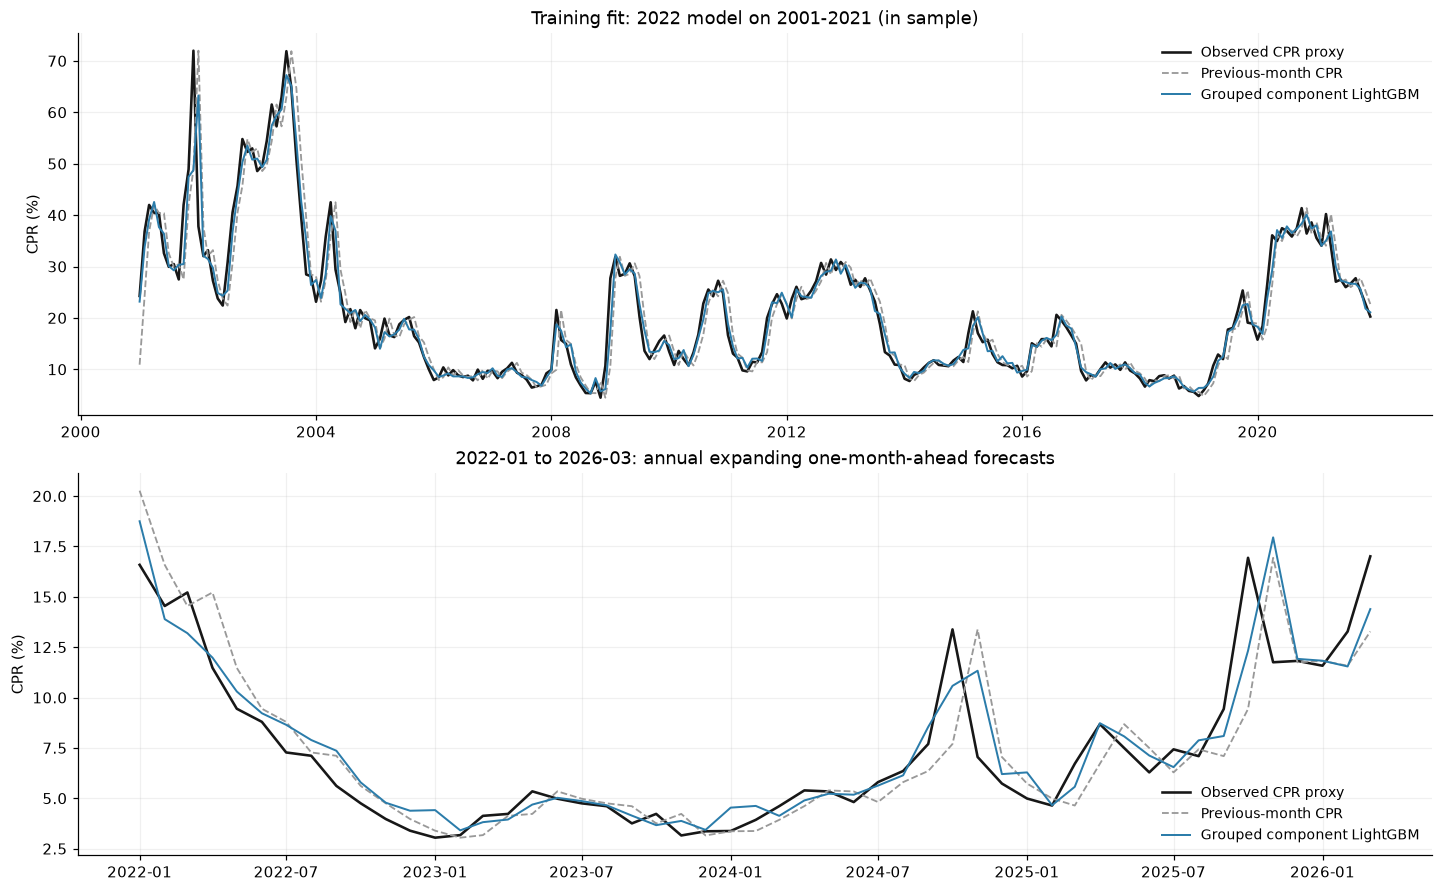

In [13]:
training_view = panel[panel.t.between(setup["training_start_t"], 2021 * 12 + 11)]
training_fit = portfolio_forecast(training_view, predict_components(fitted_by_year[2022], training_view))
fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True)
for ax, path, title in [(axes[0], training_fit, "Training fit: 2022 model on 2001-2021 (in sample)"),
                         (axes[1], forecasts, "2022-01 to 2026-03: annual expanding one-month-ahead forecasts")]:
    ax.plot(path.date, path.actual_cpr, color="#171717", lw=1.7, label="Observed CPR proxy")
    ax.plot(path.date, path.baseline_cpr, color="#999999", ls="--", lw=1.2, label="Previous-month CPR")
    ax.plot(path.date, path.predicted_cpr, color="#2b7caa", lw=1.3, label="Grouped component LightGBM")
    ax.set(title=title, ylabel="CPR (%)")
    ax.legend(fontsize=9)
plt.show()

## 7. Component forecasts

Turnover and refinance use the same exposure denominator. The reference curves below are the **estimated component labels**; only total early full payoff is directly observed. Values are monthly SMM, not annualized component CPR.

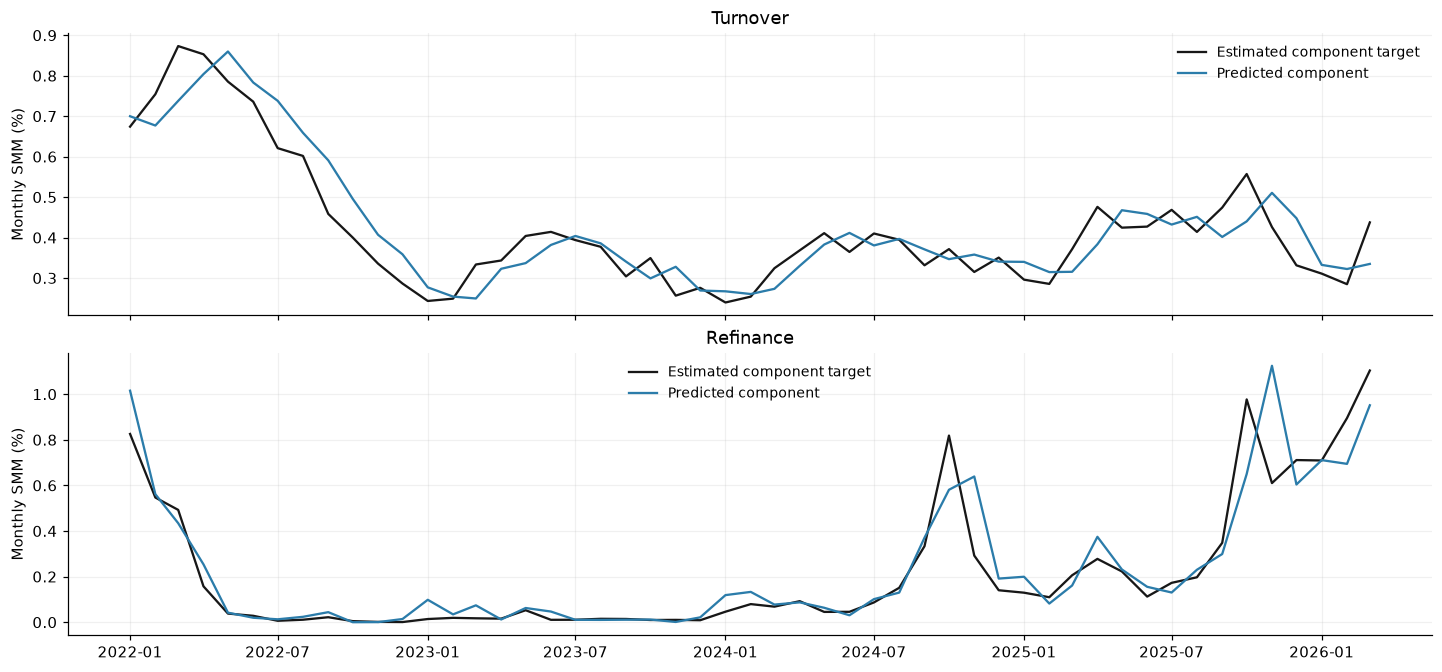

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True)
for ax, predicted, target, title in [(axes[0], "pred_turn", "estimated_turn_smm", "Turnover"),
                                      (axes[1], "pred_refi", "estimated_refi_smm", "Refinance")]:
    ax.plot(forecasts.date, 100 * forecasts[target], color="#171717", label="Estimated component target")
    ax.plot(forecasts.date, 100 * forecasts[predicted], color="#2b7caa", label="Predicted component")
    ax.set(title=title, ylabel="Monthly SMM (%)")
    ax.legend(fontsize=9)
plt.show()

## 8. What drives the grouped model?

Native SHAP contributions explain the 2025 models' **raw component SMM changes**, before non-negative clipping and CPR annualization. The chart aggregates mean absolute contributions with known group-balance weights. These are predictive contributions, not causal effects or additive final-CPR contributions.

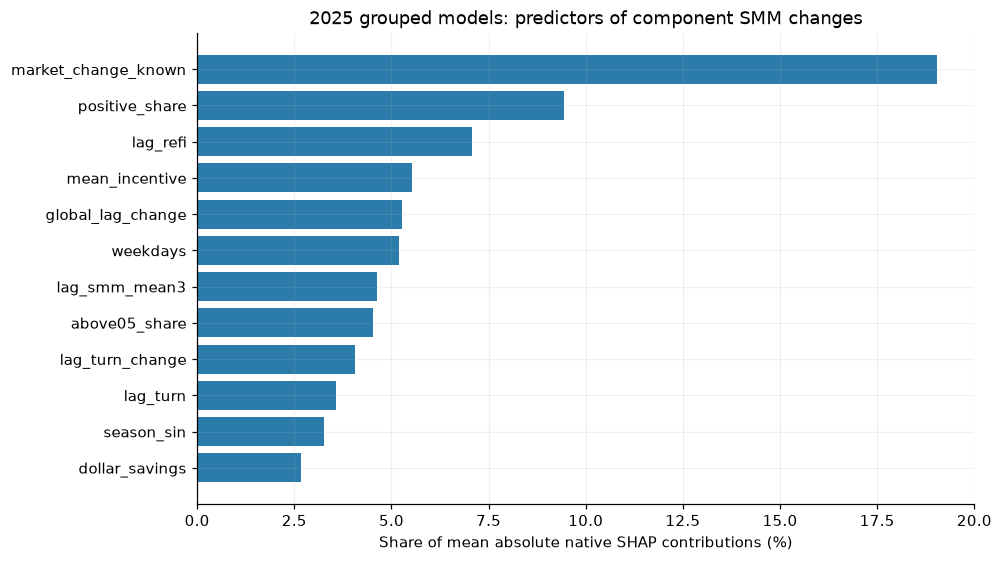

In [15]:
rows = panel[panel.t.between(2025 * 12, 2025 * 12 + 11)]
fitted = fitted_by_year[2025]
x = fitted["scaler"].transform(fitted["imputer"].transform(rows[FEATURES].replace([np.inf, -np.inf], np.nan)))
contributions = [m.booster_.predict(x, pred_contrib=True) for m in fitted["models"]]
assert all(np.allclose(c.sum(axis=1), m.booster_.predict(x), atol=1e-8)
           for c, m in zip(contributions, fitted["models"]))
impact = sum(np.average(np.abs(c[:, :-1]), axis=0, weights=rows.q) for c in contributions)
importance = pd.DataFrame({"Predictor": FEATURES, "Mean absolute contribution": impact})
importance["Share (%)"] = 100 * importance["Mean absolute contribution"] / importance["Mean absolute contribution"].sum()
importance = importance.sort_values("Share (%)", ascending=False)
top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.barh(top.Predictor, top["Share (%)"], color="#2b7caa")
ax.set(title="2025 grouped models: predictors of component SMM changes",
       xlabel="Share of mean absolute native SHAP contributions (%)")
plt.show()

## Scope and interpretation

- The target is a sampled voluntary full-payoff CPR proxy, not national-market or security-pool CPR. It excludes curtailments and does not exactly net all scheduled principal.
- Turnover/refinance labels depend on an incentive-based identification rule; origination purpose is a predictor, not an observed payoff reason.
- Annual refits and monthly observed lag updates are explicit. Prior-month reporting availability is idealized; actual release-date forecasting still needs separate validation.
- The pre-2022 validation recipe is frozen, but the 2022+ years were already explored in this project. Historical gains do not guarantee future gains.

Rate data: [Freddie PMMS on FRED](https://fred.stlouisfed.org/series/MORTGAGE30US). Incentive definitions were motivated by the team discussion and [Amine's November 5 notebook](https://github.com/AmineSlaoui/mbs-prepay/blob/4da4350743af2287d0b594a15e761970e83ee6a0/notebooks/05_market_rate_incentive.ipynb).

Tested environment: Python 3.12.2, NumPy 2.5.4, pandas 3.1.1, PyArrow 26.0.1, scikit-learn 1.9.1, LightGBM 4.7.0 and Matplotlib 3.11.2. A fresh environment needs these packages; the notebook does not install them automatically. Keep this notebook saved on disk so the default loader can read its embedded inputs.